In [1]:
import os

# os.environ["CUDA_VISIBLE_DEVICES"] = ""

In [2]:
import numpy as np

import torch
from torch import nn
from torch.nn import functional as F
torch.jit.script = lambda x: x

import re 
import h5py
from glob import glob
from functools import partial
from tqdm import tqdm

# from tensorflow.python.summary.summary_iterator import summary_iterator
# from tensorflow.compat.v1.train import summary_iterator
from tensorboard.backend.event_processing.event_file_loader import EventFileLoader

def summary_iterator(event_file):
    """
    流式读取 events 文件，逐条 yield event 对象。
    兼容原来 tensorflow.compat.v1.train.summary_iterator 的返回格式。
    """
    loader = EventFileLoader(event_file)
    for event in loader.Load():
        yield event

def get_scalar_value(v):
    if v.HasField('simple_value'):
        return v.simple_value
    elif v.HasField('tensor') and len(v.tensor.float_val) > 0:
        return v.tensor.float_val[0]
    return 0.0


from sklearn import metrics
from sklearn.metrics import roc_curve, auc, roc_auc_score
from sklearn.metrics import accuracy_score, recall_score, precision_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from scipy.spatial.distance import pdist, cdist
from scipy import stats

from transformercvn.network.trainers.neutrino_full_dense_trainer import NeutrinoFullDenseTrainer, sparse_to_dense
from transformercvn.network.trainers.neutrino_full_sparse_trainer import NeutrinoFullSparseTrainer
from transformercvn.network.trainers.neutrino_full_sdxl_trainer import NeutrinoFullSDXLTrainer
from transformercvn.dataset.minkowski_dataset import MinkowskiCollection
from transformercvn.options import Options

from matplotlib import pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
import cmasher as cmr
import seaborn as sb

/usr/lib/python3/dist-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"
/usr/local/lib/python3.10/dist-packages/MinkowskiEngine/__init__.py:36: UserWarning: The environment variable `OMP_NUM_THREADS` not set. MinkowskiEngine will automatically set `OMP_NUM_THREADS=16`. If you want to set `OMP_NUM_THREADS` manually, please export it on the command line before running a python script. e.g. `export OMP_NUM_THREADS=12; python your_program.py`. It is recommended to set it below 24.
  warnings.warn(
/home/binzhang/.local/lib/python3.10/site-packages/torchvision/io/image.py:13: UserWarning: Failed to load image Python extension: libtorch_cuda_cu.so: cannot open shared object file: No such file or directory
  warn(f"Failed to load image Python extension: {e}")


# Training History

In [3]:
tags = ['lr-AdamW/pg1',  # Learning Rate
        'val_epoch_accuracy', 'event_epoch_accuracy', 'prong_epoch_accuracy', # Validation accuracy, val = (event + prong)/2
        'train_loss', 'train_event_accuracy', 'train_prong_accuracy', # Possibly not helpful with small batch size
        'val_epoch_AUC', 'event_epoch_AUC', 'prong_epoch_AUC'] # ROC AUC, average='weighted'

In [4]:
# If training was stopped and restarted many times, this list can contain many tensorboards
# tensorboards = ["./tutorial_dense/version_0/events.out.tfevents.1745284328.jupyter-ayankele.5847.0"]
tensorboards = ["/home/binzhang/dune-transformercvn/tutorial_dense/version_4/events.out.tfevents.1786657984.tau-neutrino.1095849.0"]

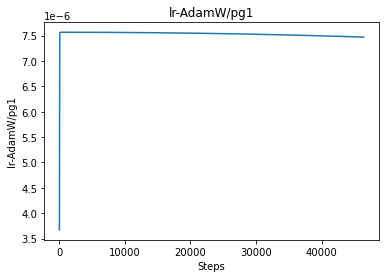

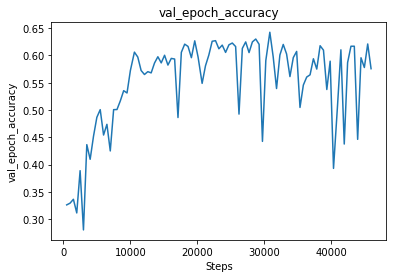

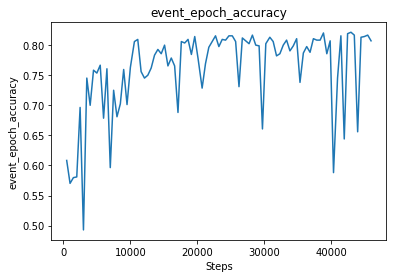

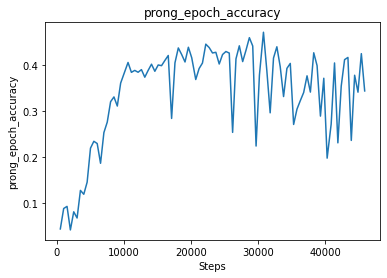

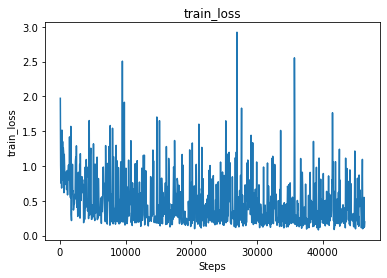

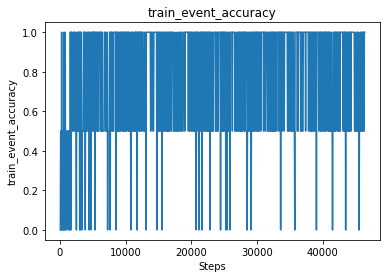

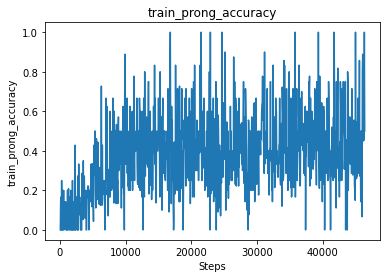

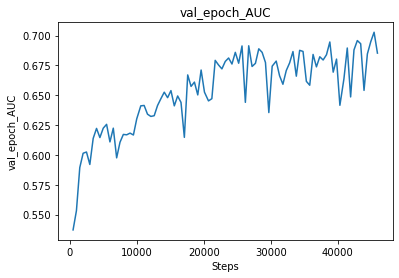

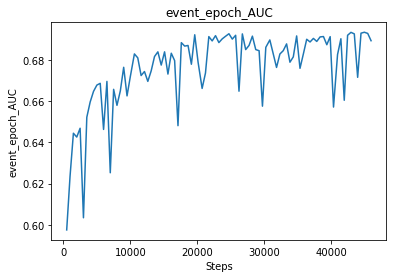

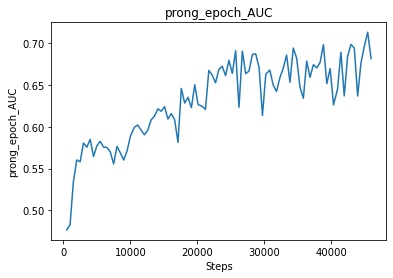

In [34]:
metrics = {tag:[] for tag in tags}

for tensorboard in tensorboards:
  for e in summary_iterator(tensorboard):
    for v in e.summary.value:
      #print(v)
      if v.tag in tags:
        val = get_scalar_value(v)
        metrics[v.tag].append([e.step, val])
#         metrics[v.tag].append([e.step, v.simple_value])
        last_step = e.step

for tag in tags:
    metric = np.array(metrics[tag])
    if metric.size==0:
        print("No values saved for metric", tag)
        continue
    plt.plot(metric[:,0], metric[:,1], label=tag)
    plt.xlabel('Steps')
    plt.ylabel(tag)
    plt.title(tag)
    #plt.legend()
    plt.show()

# Testing Dataset

In [6]:
CUDA = True
CUDA_DEVICE = 0
USE_TEX = False

#Specify a sperate testing file here if you have one. Otherwise, the validation dataset will be used.
TESTING_FILE = None

GRADIENT = False

NETWORK = NeutrinoFullDenseTrainer
#NETWORK = NeutrinoFullDenseTrainer
#NETWORK = NeutrinoFullSDXLTrainer

In [7]:
BASE_DIRECTORY = "./tutorial_dense/version_4/"
#CHECKPOINT_PATH = "./tutorial_dense/version_0/checkpoints/last.ckpt"
CHECKPOINT_PATH = "./tutorial_dense/version_4/checkpoints/last.ckpt"

In [8]:
options = Options.load(f"{BASE_DIRECTORY}/options.json")
if TESTING_FILE:
    options.testing_file = TESTING_FILE
else:
    options.testing_file = options.training_file
options.num_dataloader_workers = 0

if CHECKPOINT_PATH is None:
    checkpoints = glob(f"{BASE_DIRECTORY}/checkpoints/epoch*.ckpt")
    last_checkpoint = np.argmax([int(re.search("step=(.*).ckpt", s)[1]) for s in checkpoints])
    checkpoint_path = checkpoints[last_checkpoint]
else:
    checkpoint_path = CHECKPOINT_PATH
checkpoint = torch.load(checkpoint_path, map_location='cpu')
state_dict = checkpoint["state_dict"]
print(f"Loading from: {checkpoint_path}")

network = NETWORK(options)
network.load_state_dict(state_dict)

network = network.eval()

if not GRADIENT:
    for parameter in network.parameters():
        parameter.requires_grad_(False)

if CUDA:
    network = network.cuda(CUDA_DEVICE)

Loading from: ./tutorial_dense/version_4/checkpoints/last.ckpt


In [9]:
#DATASET = network.training_dataset
if TESTING_FILE:
    DATASET = network.testing_dataset
else:
    DATASET = network.validation_dataset

In [10]:
np.bincount(DATASET.event_targets)

array([461, 225, 155])

In [11]:
dataloader_options = network.dataloader_options
dataloader_options["pin_memory"] = False
dataloader_options["num_workers"] = 0
dataloader_options["batch_size"] = 16
dataloader_options["drop_last"] = False

test_dataloader = network.dataloader(DATASET, **dataloader_options)

In [12]:
batch = next(iter(network.dataloader(DATASET, **dataloader_options)))

if CUDA:
    batch = [b.cuda(CUDA_DEVICE) for b in batch]

(
        features,
        extra,
        event_coordinates,
        event_pixel_values,
        event_masks,
        prong_coordinates,
        prong_pixel_values,
        prong_masks,
        event_target,
        prong_target
) = batch

event_logits, prong_logits = network.forward(
        features,
        extra,
        event_coordinates,
        event_pixel_values,
        event_masks,
        prong_coordinates,
        prong_pixel_values,
        prong_masks,
    )

In [13]:
event_predictions = []
prong_predictions = []

event_targets = []
prong_targets = []

event_raws = []
prong_raws = []

total_attentions = []

for batch_idx, batch in enumerate(tqdm(test_dataloader)):
    if CUDA:
        batch = [b.cuda(CUDA_DEVICE) for b in batch]
        
    (
            features,
            extra,
            event_coordinates,
            event_pixel_values,
            event_masks,
            prong_coordinates,
            prong_pixel_values,
            prong_masks,
            event_target,
            prong_target
    ) = batch
    
    event_logits, prong_logits = network.forward(
            features,
            extra,
            event_coordinates,
            event_pixel_values,
            event_masks,
            prong_coordinates,
            prong_pixel_values,
            prong_masks,
        )
    
    event_predictions.append(event_logits.argmax(-1).cpu())
    prong_predictions.append(prong_logits.argmax(-1).cpu())
    
    event_targets.append(event_target.cpu())
    prong_targets.append(prong_target.cpu())
    
    event_raws.append(event_logits.cpu())
    prong_raws.append(prong_logits.cpu())
            
event_targets = torch.cat(event_targets)
prong_targets = torch.cat(prong_targets)

event_predictions = torch.cat(event_predictions)
prong_predictions = torch.cat(prong_predictions)

event_raws = torch.cat(event_raws)
prong_raws = torch.cat(prong_raws)

prong_mask = prong_targets >= 0

100%|██████████████| 53/53 [00:07<00:00,  7.31it/s]


In [14]:
event_probabilities = torch.softmax(event_raws, dim=1)
prong_probabilities = torch.softmax(prong_raws, dim=2)

In [15]:
flat_prong_probabilities = prong_probabilities[prong_mask]
flat_prong_predictions = prong_predictions[prong_mask]
flat_prong_targets = prong_targets[prong_mask]

In [16]:
event_probabilities # Score for [NumuCC, NueCC, NC, Other]

tensor([[0.0341, 0.6908, 0.2735, 0.0015],
        [0.0272, 0.8315, 0.1388, 0.0024],
        [0.1259, 0.1064, 0.7656, 0.0021],
        ...,
        [0.1662, 0.5159, 0.3160, 0.0019],
        [0.0996, 0.7007, 0.1967, 0.0030],
        [0.5845, 0.2213, 0.1925, 0.0017]])

In [17]:
event_targets

tensor([1, 1, 2, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2,
        2, 1, 1, 2, 1, 2, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2,
        1, 1, 1, 1, 1, 2, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 2, 1, 2, 1, 1, 2, 1, 1, 1, 2, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 2, 2, 1, 1, 1, 1, 2, 1, 2, 1, 2,
        1, 1, 1, 1, 1, 1, 1, 2, 2, 1, 1, 1, 2, 1, 1, 1, 1, 2, 2, 2, 0, 2, 0, 2,
        0, 0, 2, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 2, 2, 2, 0, 0, 0, 2, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        2, 2, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 2, 0, 0, 0, 2, 0, 0, 2, 0, 2, 0,
        0, 2, 2, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 1, 0, 2, 0, 0, 0, 0, 0, 0, 0,
        0, 2, 0, 0, 2, 0, 2, 2, 0, 0, 2, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0,
        0, 1, 0, 0, 0, 2, 1, 0, 2, 0, 0,

In [18]:
prong_probabilities # Score for [Electron, Muon, Proton, Neutron,
                    #            Pi +/-, Pi0, Photon, Other]

tensor([[[0.5616, 0.0128, 0.0924,  ..., 0.1451, 0.0397, 0.0222],
         [0.2301, 0.0238, 0.2594,  ..., 0.2225, 0.0367, 0.0435],
         [0.2097, 0.0220, 0.3135,  ..., 0.2077, 0.0291, 0.0370],
         ...,
         [0.0952, 0.1567, 0.1202,  ..., 0.0485, 0.1309, 0.1669],
         [0.0952, 0.1567, 0.1202,  ..., 0.0485, 0.1309, 0.1669],
         [0.0952, 0.1567, 0.1202,  ..., 0.0485, 0.1309, 0.1669]],

        [[0.6367, 0.0171, 0.0575,  ..., 0.1249, 0.0356, 0.0153],
         [0.3728, 0.0219, 0.1555,  ..., 0.1625, 0.0619, 0.0505],
         [0.4123, 0.0216, 0.1197,  ..., 0.1740, 0.0631, 0.0474],
         ...,
         [0.0952, 0.1567, 0.1202,  ..., 0.0485, 0.1309, 0.1669],
         [0.0952, 0.1567, 0.1202,  ..., 0.0485, 0.1309, 0.1669],
         [0.0952, 0.1567, 0.1202,  ..., 0.0485, 0.1309, 0.1669]],

        [[0.2176, 0.1289, 0.1367,  ..., 0.1688, 0.0622, 0.0613],
         [0.2079, 0.1347, 0.1425,  ..., 0.1615, 0.0630, 0.0626],
         [0.0952, 0.1567, 0.1202,  ..., 0.0485, 0.1309, 0.

In [19]:
prong_targets

tensor([[ 0,  6,  2,  ..., -1, -1, -1],
        [ 0,  0,  0,  ..., -1, -1, -1],
        [ 2,  2, -1,  ..., -1, -1, -1],
        ...,
        [ 0,  2,  0,  ...,  5, -1, -1],
        [ 0,  5,  5,  ..., -1, -1, -1],
        [ 0,  2, -1,  ..., -1, -1, -1]], dtype=torch.int8)

In [20]:
with h5py.File(BASE_DIRECTORY+"eval_predictions.h5", "w") as file:
    file.create_dataset("event_probabilities", data=event_probabilities.numpy())
    file.create_dataset("event_predictions", data=event_predictions.numpy())
    file.create_dataset("event_targets", data=event_predictions.numpy())
    
    file.create_dataset("prong_probabilities", data=prong_probabilities.numpy())
    file.create_dataset("prong_predictions", data=prong_predictions.numpy())
    file.create_dataset("prong_targets", data=prong_targets.numpy())

# Testing Metrics

In [21]:
event_classes = ["NumuCC", "NueCC", "NC", "Other"]
prong_classes = ["Electron", "Muon", "Proton", "Neutron", "Pi+/-", "Pi0", "Photon", "Other"]
prong_classes_5class = ["Electron", "Muon", "Proton", "Pi+/-", "Pi0/Photon"]

In [22]:
print("Event Target Shape: ", event_targets.shape)
print("Event Probability Shape: ", event_probabilities.shape)
print("Prong Target Shape: ", flat_prong_targets.shape)
print("Prong Probability Shape: ", flat_prong_probabilities.shape)

print()

print(f"Event Accuracy: {accuracy_score(event_targets, event_predictions):.3f}")
print(f"Event Precision: {precision_score(event_targets, event_predictions, average='weighted'):.3f}")
print(f"Event Recall: {recall_score(event_targets, event_predictions, average='weighted'):.3f}")
print(f"Event ROC AUC: {roc_auc_score(event_targets, event_probabilities, multi_class='ovr', average='weighted'):.3f}")

print()

print(f"Prong Accuracy: {accuracy_score(flat_prong_targets, flat_prong_predictions):.3f}")
print(f"Prong Precision: {precision_score(flat_prong_targets, flat_prong_predictions, average='weighted'):.3f}")
print(f"Prong Recall: {recall_score(flat_prong_targets, flat_prong_predictions, average='weighted'):.3f}")
print(f"Prong ROC AUC: {roc_auc_score(flat_prong_targets, flat_prong_probabilities, multi_class='ovr', average='weighted'):.3f}")

Event Target Shape:  torch.Size([841])
Event Probability Shape:  torch.Size([841, 4])
Prong Target Shape:  torch.Size([4750])
Prong Probability Shape:  torch.Size([4750, 8])

Event Accuracy: 0.822
Event Precision: 0.817
Event Recall: 0.822


ValueError: Number of classes in y_true not equal to the number of columns in 'y_score'

In [23]:
# Check event classification performance
event_aucs = roc_auc_score(
    event_targets.numpy(),
    event_probabilities.numpy(),
    average=None,
    multi_class="ovr"
)

print(f"NumuCC ROC AUC: {event_aucs[0]:.3f}")
print(f"NueCC ROC AUC: {event_aucs[1]:.3f}")
print(f"NC ROC AUC: {event_aucs[2]:.3f}")
print(f"Other AUC: {event_aucs[3]:.3f}")

ValueError: Number of classes in y_true not equal to the number of columns in 'y_score'

In [24]:
# Check prong classification performance
prong_aucs = roc_auc_score(
    flat_prong_targets.numpy(),
    flat_prong_probabilities.numpy(),
    average=None,
    multi_class="ovr"
)

print(f"Electron ROC AUC: {prong_aucs[0]:.3f}")
print(f"Muon ROC AUC: {prong_aucs[1]:.3f}")
print(f"Proton ROC AUC: {prong_aucs[2]:.3f}")
print(f"Neutron AUC: {prong_aucs[3]:.3f}")
print(f"Charged Pion ROC AUC: {prong_aucs[4]:.3f}")
print(f"Neutral Pion ROC AUC: {prong_aucs[5]:.3f}")
print(f"Photon ROC AUC: {prong_aucs[6]:.3f}")
print(f"Other AUC: {prong_aucs[7]:.3f}")

Electron ROC AUC: 0.855
Muon ROC AUC: 0.919
Proton ROC AUC: 0.786
Neutron AUC: 0.606
Charged Pion ROC AUC: 0.606
Neutral Pion ROC AUC: 0.700
Photon ROC AUC: 0.560
Other AUC: 0.597


In [25]:
for i in range(3):
    plt.figure(figsize=[5.5,5.2])
    fpr,tpr,thr = roc_curve(event_targets, event_probabilities[:,i], pos_label=i, drop_intermediate=False)
    plt.plot(fpr,tpr, label = "%s, AUC = %.4f" % (event_classes[i],event_aucs[i]))
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend(loc='lower right')

NameError: name 'event_aucs' is not defined

<Figure size 396x374.4 with 0 Axes>

ValueError: The number of FixedLocator locations (3), usually from a call to set_ticks, does not match the number of ticklabels (4).

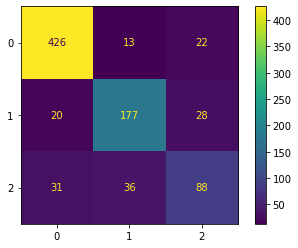

In [26]:
err_mat = confusion_matrix(event_targets, event_predictions)
disp = ConfusionMatrixDisplay(confusion_matrix=err_mat, display_labels=event_classes)
disp.plot()

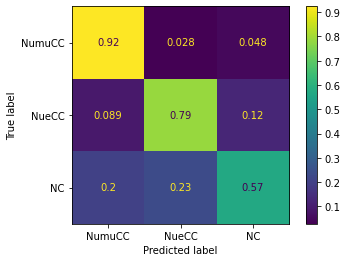

In [27]:
err_mat = confusion_matrix(event_targets, event_predictions, normalize='true', labels=[0,1,2])
disp = ConfusionMatrixDisplay(confusion_matrix=err_mat, display_labels=event_classes[:3])
disp.plot()

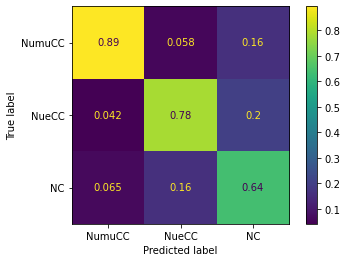

In [28]:
err_mat = confusion_matrix(event_targets, event_predictions, normalize='pred', labels=[0,1,2])
disp = ConfusionMatrixDisplay(confusion_matrix=err_mat, display_labels=event_classes[:3])
disp.plot()

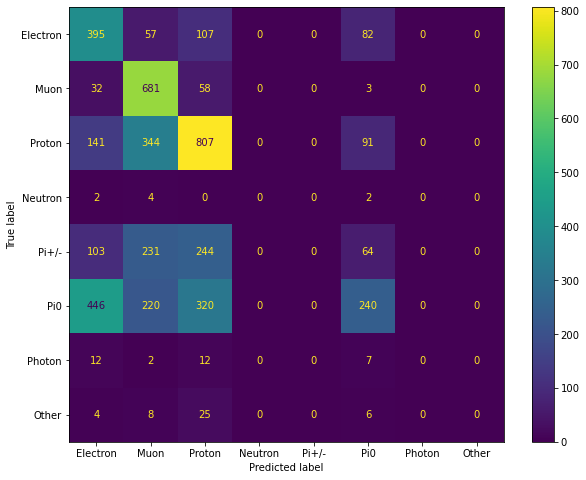

In [29]:
# "Neutron" and "Pi0" indicate photons from mother neutron/Pi0
# "Photon" indicates all other photons
err_mat = confusion_matrix(flat_prong_targets, flat_prong_predictions)
disp = ConfusionMatrixDisplay(confusion_matrix=err_mat, display_labels=prong_classes)
fig,ax=plt.subplots(figsize=[10,8])
disp.plot(ax=ax)

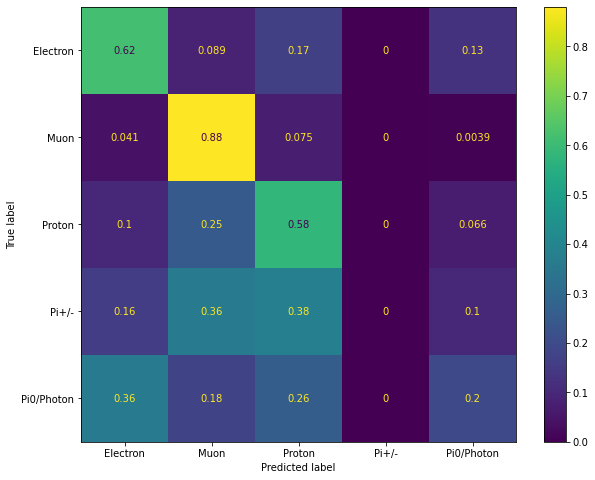

In [30]:
err_mat = confusion_matrix(flat_prong_targets, flat_prong_predictions, normalize='true', labels=[0,1,2,4,5])
disp = ConfusionMatrixDisplay(confusion_matrix=err_mat, display_labels=prong_classes_5class)
fig,ax=plt.subplots(figsize=[10,8])
disp.plot(ax=ax)

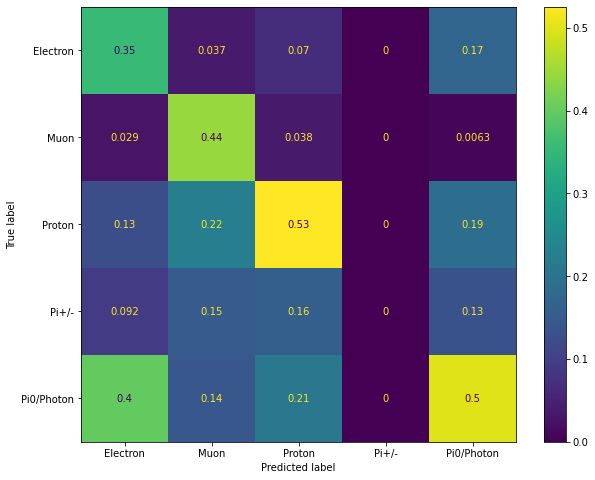

In [31]:
err_mat = confusion_matrix(flat_prong_targets, flat_prong_predictions, normalize='pred', labels=[0,1,2,4,5])
disp = ConfusionMatrixDisplay(confusion_matrix=err_mat, display_labels=prong_classes_5class)
fig,ax=plt.subplots(figsize=[10,8])
disp.plot(ax=ax)

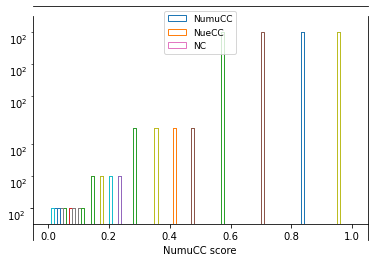

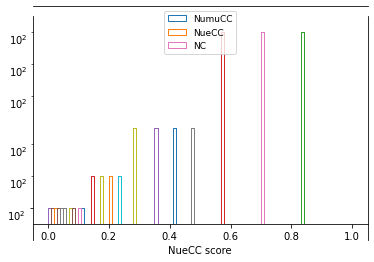

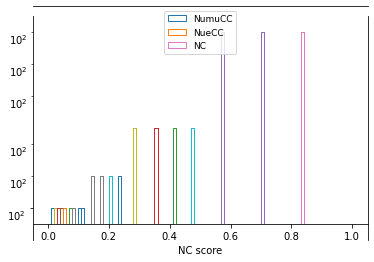

In [32]:
for iScoreClass in range(3):
  for iTrueClass in range(3):
    bins=np.arange(0,1.01,.01)
    
    plt.hist(event_probabilities[:,iScoreClass][event_targets==iTrueClass], bins=bins, histtype='step', label=event_classes[iTrueClass], density=True)

  plt.legend(loc='upper center', fontsize='9')
  plt.yscale('log')
  plt.xlabel(event_classes[iScoreClass] + " score")  
  plt.show()

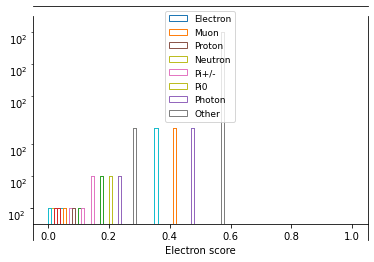

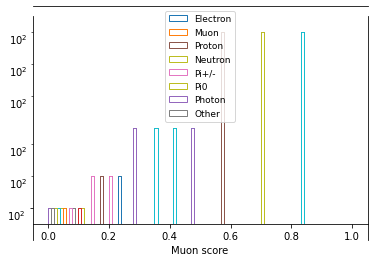

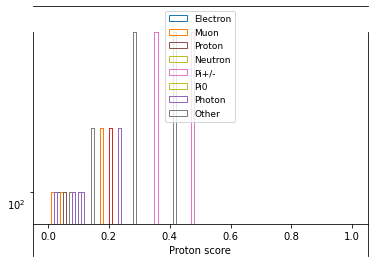

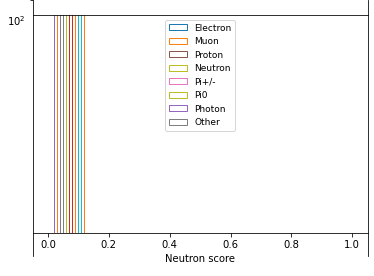

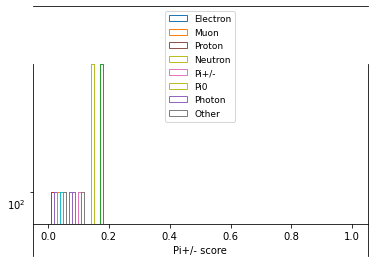

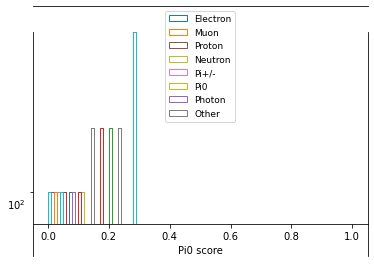

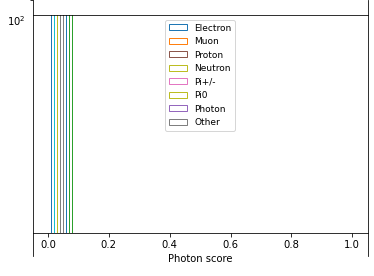

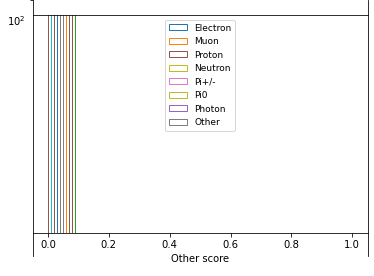

In [33]:
for iScoreClass in range(8):
  for iTrueClass in range(8):
    bins=np.arange(0,1.01,.01)
    
    plt.hist(flat_prong_probabilities[:,iScoreClass][flat_prong_targets==iTrueClass], bins=bins, histtype='step', label=prong_classes[iTrueClass], density=True)

  plt.legend(loc='upper center', fontsize='9')
  plt.yscale('log')
  plt.xlabel(prong_classes[iScoreClass] + " score")  
  plt.show()